In [2]:
!pip install shap imbalanced-learn pyarrow -q

import pandas as pd, numpy as np, warnings, json, os, re, joblib
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, precision_score, recall_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import xgboost as xgb
from scipy.stats import chi2, rankdata
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive")

SOURCE_DATA = "/content/drive/MyDrive/model_ready_dataset_1.xlsx"
OUT_DIR    = "/content/drive/MyDrive/cinque_oulad"
os.makedirs(OUT_DIR, exist_ok=True)
print("setup ok, outputs will go to", OUT_DIR)

Mounted at /content/drive
setup ok, outputs will go to /content/drive/MyDrive/cinque_oulad


In [3]:
!pip install kaggle -q
from google.colab import files
print("Upload your kaggle.json (Kaggle → Settings → API → Create New Token)")
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle*.json ~/.kaggle/kaggle.json && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d anlgrbz/student-demographics-online-education-dataoulad -p /content --unzip
!mkdir -p /content/oulad && mv /content/*.csv /content/oulad/ 2>/dev/null
!ls /content/oulad

Upload your kaggle.json (Kaggle → Settings → API → Create New Token)


Saving kaggle (1).json to kaggle (1).json
Dataset URL: https://www.kaggle.com/datasets/anlgrbz/student-demographics-online-education-dataoulad
License(s): Attribution 4.0 International (CC BY 4.0)
100% 42.2M/42.2M [00:03<00:00, 11.2MB/s]

assessments.csv  studentAssessment.csv	studentRegistration.csv  vle.csv
courses.csv	 studentInfo.csv	studentVle.csv


In [ ]:
!mkdir -p /content/oulad && mv /content/*.csv /content/oulad/ && ls /content/oulad

assessments.csv  studentAssessment.csv	studentRegistration.csv  vle.csv
courses.csv	 studentInfo.csv	studentVle.csv


In [4]:
info = pd.read_csv("/content/oulad/studentInfo.csv")
print("studentInfo:", info.shape)
print("final_result distribution:")
print(info.final_result.value_counts(normalize=True).round(3))

# LABEL DECISION: Withdrawn only (construct-match with Source at-risk)
info["target"] = (info.final_result == "Withdrawn").astype(int)

print(f"\nOULAD raw: n={len(info):,}, at-risk={info.target.sum():,} ({info.target.mean()*100:.1f}%)")
print( "Source:     n=3,325, at-risk=565 (17.0%)  [for comparison]")

studentInfo: (32593, 12)
final_result distribution:
final_result
Pass           0.379
Withdrawn      0.312
Fail           0.216
Distinction    0.093
Name: proportion, dtype: float64

OULAD raw: n=32,593, at-risk=10,156 (31.2%)
Source:     n=3,325, at-risk=565 (17.0%)  [for comparison]


In [5]:
# CELL 4 — Assessment features (comparable to Source monthly scores)
sa   = pd.read_csv("/content/oulad/studentAssessment.csv")
asmt = pd.read_csv("/content/oulad/assessments.csv")
sa = sa.merge(asmt[["id_assessment","code_module","code_presentation","assessment_type","date"]],
              on="id_assessment", how="left")
sa = sa[sa.assessment_type == "TMA"].sort_values(
    ["id_student","code_module","code_presentation","date"])

def improvement(x):
    return float(x.iloc[-1] - x.iloc[0]) if len(x) > 1 else 0.0

scores = (sa.groupby(["id_student","code_module","code_presentation"])
            .agg(total_score=("score","mean"),
                 std_module_score=("score","std"),
                 score_improvement=("score", improvement),
                 n_assessments=("score","count"))
            .reset_index())
scores["std_module_score"] = scores["std_module_score"].fillna(0)
print("scores aggregated:", scores.shape)
scores.head(3)

scores aggregated: (24820, 7)


,id_student,code_module,code_presentation,total_score,std_module_score,score_improvement,n_assessments
0,6516,AAA,2014J,61.800000,10.329569,17.0,5
1,8462,DDD,2013J,87.666667,5.033223,-6.0,3
2,8462,DDD,2014J,86.500000,4.725816,-6.0,4


In [6]:
# CELL 5 — Engagement features from studentVle (the big one)
CKPT = f"{OUT_DIR}/oulad_engagement.parquet"
if os.path.exists(CKPT):
    eng = pd.read_parquet(CKPT)
    print("loaded engagement from checkpoint")
else:
    vle = pd.read_csv("/content/oulad/studentVle.csv")
    print("VLE rows:", len(vle))
    eng = (vle.groupby(["id_student","code_module","code_presentation"])
              .agg(n_clicks=("sum_click","sum"),
                   n_sessions=("date","nunique"),
                   engagement_span_days=("date", lambda x: int(x.max()-x.min())))
              .reset_index())
    eng.to_parquet(CKPT)
    print("engagement aggregated:", eng.shape, "-> checkpointed")
eng.head(3)

loaded engagement from checkpoint


,id_student,code_module,code_presentation,n_clicks,n_sessions,engagement_span_days
0,6516,AAA,2014J,2791,159,292
1,8462,DDD,2013J,646,56,124
2,8462,DDD,2014J,10,1,0


In [7]:
# CELL 6 — Merge, build final feature matrix, encode
df = (info[["id_student","code_module","code_presentation",
            "gender","imd_band","highest_education","age_band",
            "num_of_prev_attempts","studied_credits","disability","target"]]
        .merge(scores, on=["id_student","code_module","code_presentation"], how="inner")
        .merge(eng,    on=["id_student","code_module","code_presentation"], how="inner"))
df["imd_band"] = df["imd_band"].fillna("Missing").astype(str)

print(f"after merge: {df.shape} | positives: {df.target.sum():,} ({df.target.mean()*100:.1f}%)")

# Document the population restriction as an external-validity boundary
raw_withdrawn = int((info.final_result == "Withdrawn").sum())
kept_withdrawn = int(df.target.sum())
excluded_withdrawn = raw_withdrawn - kept_withdrawn
print(f"\nPopulation restriction (both TMA + VLE required):")
print(f"  Withdrawn students in raw:  {raw_withdrawn:,}")
print(f"  Retained after restriction: {kept_withdrawn:,}")
print(f"  Excluded (documented):      {excluded_withdrawn:,} ({excluded_withdrawn/raw_withdrawn*100:.1f}%)")

after merge: (24772, 18) | positives: 4,155 (16.8%)

Population restriction (both TMA + VLE required):
  Withdrawn students in raw:  10,156
  Retained after restriction: 4,155
  Excluded (documented):      6,001 (59.1%)


In [8]:
#CELL 7
# Percentile transform on engagement (CAN-DO Step 2 — scale invariance)
def to_pct(s):
    a = np.asarray(s, dtype=float)
    r = rankdata(a, method="average")
    return 100.0 * (r - 1) / (len(r) - 1) if len(r) > 1 else np.zeros_like(a)

for col in ["n_clicks", "n_sessions", "engagement_span_days"]:
    df[col + "_pct"] = to_pct(df[col])
df = df.drop(columns=["n_clicks", "n_sessions", "engagement_span_days"])

# Source side (in-memory only; .xlsx not touched)
source_df = pd.read_excel(SOURCE_DATA)
source_pct = source_df.copy()
for raw in ["n_module_views", "n_logins", "engagement_span_days"]:
    if raw in source_pct.columns:
        source_pct[raw + "_pct"] = to_pct(source_pct[raw])
        source_pct = source_pct.drop(columns=[raw])

# Encode OULAD categoricals
cat_cols = ["gender","imd_band","highest_education","age_band",
            "disability","code_module","code_presentation"]
X = pd.get_dummies(df.drop(columns=["id_student","target"]), columns=cat_cols)

# Sanitize column names (fixes imd_band_10-20% -> imd_band_10_20_)
X.columns = [re.sub(r'[^A-Za-z0-9_]+', '_', c) for c in X.columns]

# Mean-impute (small residual in imd_band and highest_education)
nan_before = int(X.isna().sum().sum())
X = X.fillna(X.mean(numeric_only=True))
y = df["target"].values
feature_names = X.columns.tolist()

print(f"OULAD encoded features: {X.shape[1]}")
print(f"IMD columns:            {[c for c in feature_names if c.startswith('imd_band')][:5]}")
print(f"NaNs before/after imp.: {nan_before} / {int(X.isna().sum().sum())}")

df.to_parquet(f"{OUT_DIR}/oulad_merged_pct.parquet")

OULAD encoded features: 43
IMD columns:            ['imd_band_0_10_', 'imd_band_10_20', 'imd_band_20_30_', 'imd_band_30_40_', 'imd_band_40_50_']
NaNs before/after imp.: 132 / 0


In [9]:
# CELL 8 — Grid-search independently on OULAD (SAME protocol, own winner)
def psi(a, b, bins=10):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    a = a[np.isfinite(a)]; b = b[np.isfinite(b)]
    qs = np.linspace(0, 1, bins+1)
    cuts = np.unique(np.quantile(a, qs))
    if len(cuts) < 3: return float("nan")
    pa, _ = np.histogram(a, bins=cuts); pb, _ = np.histogram(b, bins=cuts)
    pa = pa/pa.sum() + 1e-6; pb = pb/pb.sum() + 1e-6
    return float(np.sum((pb-pa) * np.log(pb/pa)))

diag = pd.DataFrame([
    ("Sample size",         f"{len(source_df):,}",                    f"{len(df):,}"),
    ("At-risk prevalence",  f"{source_df.at_risk.eq(0).mean()*100:.1f}%",
                            f"{df.target.mean()*100:.1f}%"),
    ("Encoded features",    "43",                                    str(X.shape[1])),
    ("PSI: engagement (percentile)", "-",
        f"{psi(source_pct.n_module_views_pct, df.n_clicks_pct):.2f}"),
    ("PSI: sessions (percentile)",   "-",
        f"{psi(source_pct.n_logins_pct, df.n_sessions_pct):.2f}"),
], columns=["Diagnostic","Source","OULAD"])
print(diag.to_string(index=False))
diag.to_csv(f"{OUT_DIR}/step1_diagnostics.csv", index=False)

                  Diagnostic Source  OULAD
                 Sample size 3,325 24,772
          At-risk prevalence 17.0%  16.8%
            Encoded features    43     43
PSI: engagement (percentile)     -   0.00
  PSI: sessions (percentile)     -   0.00


In [10]:
# CELL 9

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
sc = MinMaxScaler(); Xtr_s = sc.fit_transform(Xtr); Xte_s = sc.transform(Xte)
Xb, yb = SMOTE(random_state=42).fit_resample(Xtr_s, ytr)
print(f"train (post-SMOTE): {np.bincount(yb)}  |  test: {np.bincount(yte)}")

grid = {"max_depth":[4,6,8], "n_estimators":[100,200,300],
        "learning_rate":[0.01,0.1], "subsample":[0.8]}
gs = GridSearchCV(
    XGBClassifier(eval_metric="auc", random_state=42),
    grid, cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc", n_jobs=-1, verbose=1)
gs.fit(Xb, yb)
best = gs.best_params_
print("\nOULAD grid winner:", best, "| CV AUC:", round(gs.best_score_, 4))
print("Source winner (compare): {'learning_rate':0.1,'max_depth':8,'n_estimators':300,'subsample':0.8}")
json.dump(best, open(f"{OUT_DIR}/oulad_best_params.json","w"), indent=2)

train (post-SMOTE): [16493 16493]  |  test: [4124  831]
Fitting 5 folds for each of 18 candidates, totalling 90 fits

OULAD grid winner: {'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 200, 'subsample': 0.8} | CV AUC: 0.9878
Source winner (compare): {'learning_rate':0.1,'max_depth':8,'n_estimators':300,'subsample':0.8}


In [11]:
#CELL 10
full = XGBClassifier(**best, eval_metric="auc", random_state=42).fit(Xb, yb)

dm = xgb.DMatrix(Xtr_s, feature_names=feature_names)
contribs = full.get_booster().predict(dm, pred_contribs=True)[:, :-1]
mean_abs = pd.Series(np.abs(contribs).mean(axis=0), index=feature_names).sort_values(ascending=False)
cum = mean_abs.cumsum() / mean_abs.sum()
pruned_cols = list(cum[cum <= 0.95].index)
if len(pruned_cols) < len(cum):
    pruned_cols.append(cum.index[len(pruned_cols)])
print(f"pruning at 95% cumulative |SHAP|: 43 -> {len(pruned_cols)} features")

IMD_COLS = [c for c in pruned_cols if c.startswith("imd_band_")]
print(f"IMD encodings in pruned set: {len(IMD_COLS)}")
if IMD_COLS: print(f"  {IMD_COLS}")
deployed_cols = [c for c in pruned_cols if c not in IMD_COLS]
print(f"after fairness screen: {len(pruned_cols)} -> {len(deployed_cols)} features")

print("\nTop 10 features by mean |SHAP|:")
print(mean_abs.head(10).round(3))
mean_abs.to_csv(f"{OUT_DIR}/oulad_shap_values.csv")

pruning at 95% cumulative |SHAP|: 43 -> 24 features
IMD encodings in pruned set: 1
  ['imd_band_20_30_']
after fairness screen: 24 -> 23 features

Top 10 features by mean |SHAP|:
engagement_span_days_pct    3.526
n_assessments               1.219
n_sessions_pct              0.465
studied_credits             0.315
total_score                 0.245
code_module_DDD             0.231
n_clicks_pct                0.209
code_presentation_2014J     0.204
std_module_score            0.158
score_improvement           0.139
dtype: float32


In [12]:
#CELL 11
SEEDS = [42, 0, 123, 2024, 7]

def run(cols):
    aucs = []
    seed42 = None
    for s in SEEDS:
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=s)
        sc = MinMaxScaler(); Xtr_s = sc.fit_transform(Xtr[cols]); Xte_s = sc.transform(Xte[cols])
        Xb, yb = SMOTE(random_state=s).fit_resample(Xtr_s, ytr)
        m = XGBClassifier(**best, eval_metric="auc", random_state=42).fit(Xb, yb)
        p = m.predict_proba(Xte_s)[:,1]
        aucs.append(roc_auc_score(yte, p))
        if s == 42:
            seed42 = dict(p=p, y=yte, Xte=Xte)
    return np.array(aucs), seed42

results = {}
for name, cols in [("full_43", feature_names), ("pruned", pruned_cols), ("deployed", deployed_cols)]:
    a, s42 = run(cols)
    results[name] = dict(aucs=a, **s42)
    print(f"{name:10s} AUC = {a.mean():.3f} ± {a.std(ddof=1):.3f}   per-seed: {[round(x,3) for x in a]}")

# McNemar full vs pruned (seed 42)
yh_f = (results["full_43"]["p"] >= 0.5).astype(int)
yh_p = (results["pruned"]["p"]  >= 0.5).astype(int)
y42  = results["full_43"]["y"]
b = int(((yh_f == y42) & (yh_p != y42)).sum())
c = int(((yh_f != y42) & (yh_p == y42)).sum())
chi2_stat = (abs(b-c)-1)**2/(b+c) if (b+c)>0 else 0.0
p_mc = float(chi2.sf(chi2_stat, df=1)) if (b+c)>0 else 1.0
print(f"\n[McNemar] full vs pruned: b={b}, c={c}, chi2={chi2_stat:.3f}, p={p_mc:.3f}")

# Equal-opportunity gap by IMD band
def eo_by_imd(cfg):
    d = results[cfg]
    yhat = (d["p"] >= 0.5).astype(int)
    imd = df.loc[d["Xte"].index, "imd_band"].values
    rec = {}
    for band in sorted(pd.unique(imd)):
        mask = imd == band
        if mask.sum() < 30: continue
        pos = mask & (d["y"] == 1)
        if pos.sum(): rec[band] = round(float(yhat[pos].mean()), 3)
    gap = (max(rec.values()) - min(rec.values())) if rec else float("nan")
    return rec, gap

rec_p, gap_p = eo_by_imd("pruned")
rec_d, gap_d = eo_by_imd("deployed")
print(f"\nEO recall by IMD (pruned):   {rec_p}\n  gap = {gap_p:.2f}")
print(f"EO recall by IMD (deployed): {rec_d}\n  gap = {gap_d:.2f}")

full_43    AUC = 0.936 ± 0.004   per-seed: [np.float64(0.933), np.float64(0.937), np.float64(0.938), np.float64(0.942), np.float64(0.932)]
pruned     AUC = 0.936 ± 0.004   per-seed: [np.float64(0.934), np.float64(0.937), np.float64(0.936), np.float64(0.941), np.float64(0.932)]
deployed   AUC = 0.937 ± 0.004   per-seed: [np.float64(0.933), np.float64(0.938), np.float64(0.937), np.float64(0.943), np.float64(0.932)]

[McNemar] full vs pruned: b=102, c=97, chi2=0.080, p=0.777

EO recall by IMD (pruned):   {'0-10%': 0.728, '10-20': 0.716, '20-30%': 0.717, '30-40%': 0.779, '40-50%': 0.652, '50-60%': 0.72, '60-70%': 0.768, '70-80%': 0.714, '80-90%': 0.685, '90-100%': 0.661, 'Missing': 0.654}
  gap = 0.13
EO recall by IMD (deployed): {'0-10%': 0.772, '10-20': 0.688, '20-30%': 0.737, '30-40%': 0.767, '40-50%': 0.652, '50-60%': 0.68, '60-70%': 0.797, '70-80%': 0.688, '80-90%': 0.741, '90-100%': 0.643, 'Missing': 0.654}
  gap = 0.15


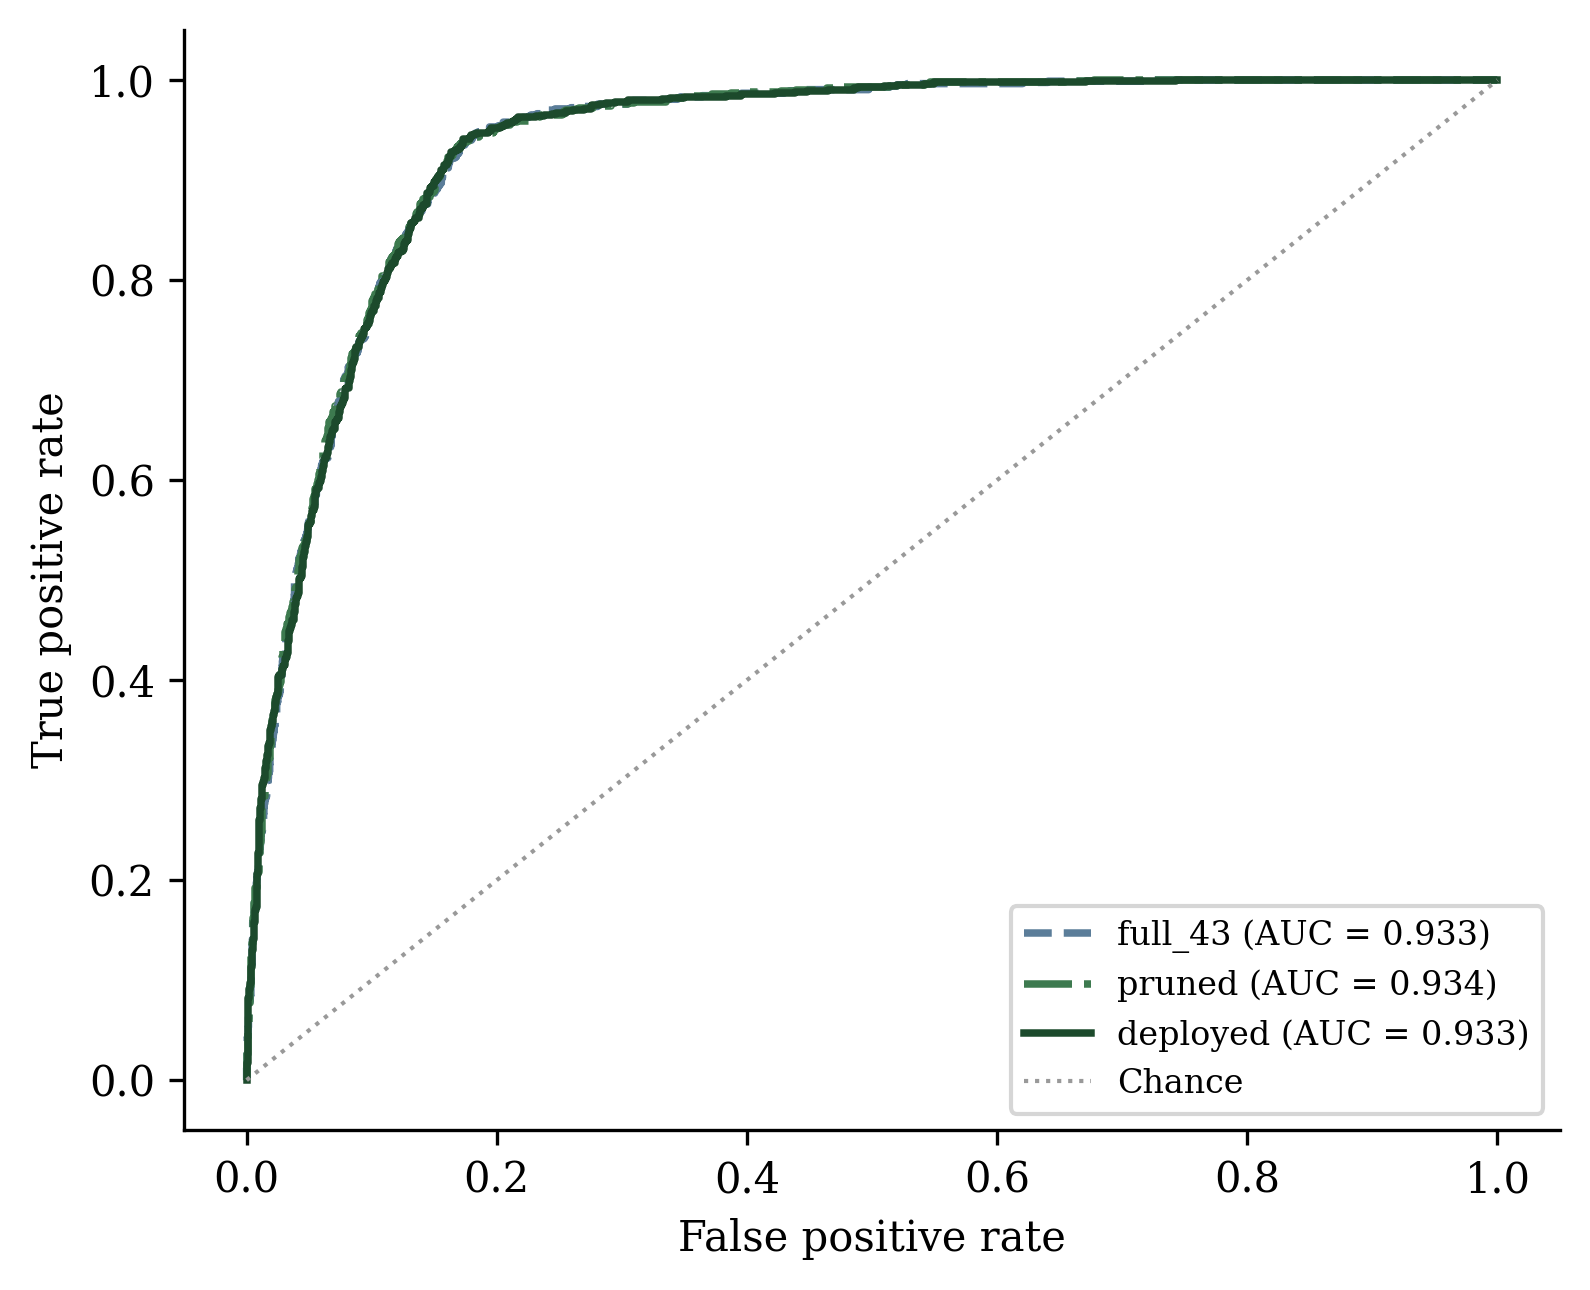


===== CROSS-CONTEXT COMPARISON =====
                                                         Source (v3)                                                    OULAD
n                                                             3,325                                                   24,772
At-risk prevalence                                            17.0%                                                    16.8%
Pruning (full → pruned)                                     43 → 28                                                  43 → 24
Full AUC (5 seeds)                                    0.875 ± 0.011                                            0.936 ± 0.004
Pruned AUC                                            0.880 ± 0.010                                            0.936 ± 0.004
Deployed AUC                                          0.870 ± 0.012                                            0.937 ± 0.004
McNemar full vs pruned (p)                                     1.00                   

In [ ]:
#CELL 12
# ROC figure
plt.rcParams.update({"font.family":"serif","font.size":10,"figure.dpi":300})
fig, ax = plt.subplots(figsize=(5.4, 4.4))
for name, ccol, ls in [("full_43","#5b7d99","--"),("pruned","#3d7a4f","-."),("deployed","#1c4a2c","-")]:
    d = results[name]
    fpr, tpr, _ = roc_curve(d["y"], d["p"])
    ax.plot(fpr, tpr, ls, color=ccol, lw=1.8,
            label=f"{name} (AUC = {roc_auc_score(d['y'],d['p']):.3f})")
ax.plot([0,1],[0,1],":",color="#999",lw=1,label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/oulad_FIG_roc.png", dpi=300); plt.show()

# Cross-context comparison
comparison = pd.DataFrame({
 "Source (v3)": ["3,325","17.0%","43 → 28",
                "0.875 ± 0.011","0.880 ± 0.010","0.870 ± 0.012",
                "1.00","0.52 (fee status)","0.44",
                "module views, logins, score consistency"],
 "OULAD":     [f"{len(df):,}", f"{df.target.mean()*100:.1f}%",
                f"43 → {len(pruned_cols)}",
                f"{results['full_43']['aucs'].mean():.3f} ± {results['full_43']['aucs'].std(ddof=1):.3f}",
                f"{results['pruned' ]['aucs'].mean():.3f} ± {results['pruned' ]['aucs'].std(ddof=1):.3f}",
                f"{results['deployed']['aucs'].mean():.3f} ± {results['deployed']['aucs'].std(ddof=1):.3f}",
                f"{p_mc:.2f}", f"{gap_p:.2f} (IMD)", f"{gap_d:.2f}",
                ", ".join(mean_abs.head(3).index.tolist())],
}, index=["n","At-risk prevalence","Pruning (full → pruned)",
         "Full AUC (5 seeds)","Pruned AUC","Deployed AUC",
         "McNemar full vs pruned (p)","ΔEO before screen","ΔEO after screen",
         "Top-3 SHAP features"])
print("\n===== CROSS-CONTEXT COMPARISON =====")
print(comparison.to_string())
comparison.to_csv(f"{OUT_DIR}/oulad_vs_source_comparison.csv")

summary = dict(
    oulad_n=int(len(df)), oulad_positive_rate=float(df.target.mean()),
    excluded_withdrawn=excluded_withdrawn,
    encoded_features=int(X.shape[1]),
    nan_before_imputation=nan_before,
    grid_winner=best,
    n_features_pruned=int(len(pruned_cols)),
    n_features_deployed=int(len(deployed_cols)),
    auc_full=(float(results["full_43"]["aucs"].mean()),
              float(results["full_43"]["aucs"].std(ddof=1))),
    auc_pruned=(float(results["pruned"]["aucs"].mean()),
                float(results["pruned"]["aucs"].std(ddof=1))),
    auc_deployed=(float(results["deployed"]["aucs"].mean()),
                  float(results["deployed"]["aucs"].std(ddof=1))),
    mcnemar=dict(b=b, c=c, chi2=chi2_stat, p=p_mc),
    imd_eo_pruned=rec_p, imd_eo_gap_pruned=gap_p,
    imd_eo_deployed=rec_d, imd_eo_gap_deployed=gap_d,
    top10_shap={k: float(v) for k, v in mean_abs.head(10).items()},
)
json.dump(summary, open(f"{OUT_DIR}/oulad_run_summary.json","w"), indent=2, default=str)
print(f"\nAll outputs saved to {OUT_DIR}")
print("Send me: step1_diagnostics.csv, oulad_vs_source_comparison.csv, oulad_run_summary.json, oulad_shap_values.csv, oulad_FIG_roc.png")

In [13]:
excluded = info[~info.set_index(["id_student","code_module","code_presentation"]).index
                 .isin(df.set_index(["id_student","code_module","code_presentation"]).index)]
print("excluded n:", len(excluded))
print("excluded Withdrawn rate:", excluded.final_result.eq("Withdrawn").mean().round(3))
print("retained  Withdrawn rate:", df.target.mean().round(3))

excluded n: 7821
excluded Withdrawn rate: 0.767
retained  Withdrawn rate: 0.168
